# PRCL-0015 · Bank GoodCredit — Credit Score Prediction
## Notebook 1: Data Exploration

**Business case.** Bank GoodCredit wants to predict a *cred score* for current credit-card customers to measure creditworthiness and reduce default risk.

**Target:** `Bad_label` — 0 = good credit history, 1 = bad credit history (30+ DPD bucket).
**Benchmark:** Gini 37.9 with a 66-feature ensemble.

**Data (MySQL `project_banking`):**
| Table | Content |
|---|---|
| `Cust_Account` | historical accounts and payment history (many rows per customer) |
| `Cust_Enquiry` | historical credit enquiries — amount and purpose |
| `Cust_Demographics` | current applications, obscured `feature_1 … feature_79`, and `Bad_label` |

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', palette='deep')
RAW = os.path.join(ROOT, 'data', 'raw')

## 1. Load the three tables

In [2]:
acc  = pd.read_csv(os.path.join(RAW, 'customer_account.csv'), dtype={'paymenthistory1': str, 'paymenthistory2': str})
enq  = pd.read_csv(os.path.join(RAW, 'customer_enquiry.csv'))
demo = pd.read_csv(os.path.join(RAW, 'customer_demographics.csv'), low_memory=False)
for name, df in [('Cust_Account', acc), ('Cust_Enquiry', enq), ('Cust_Demographics', demo)]:
    print(f'{name:18s} rows={df.shape[0]:>7,}  cols={df.shape[1]:>3}  customers={df.customer_no.nunique():,}')

Cust_Account       rows= 96,361  cols= 21  customers=15,000
Cust_Enquiry       rows=116,326  cols=  6  customers=14,958
Cust_Demographics  rows= 15,000  cols= 83  customers=15,000


In [3]:
acc.head()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,1007,03-Nov-15,2,1,23-Apr-12,27-Jul-15,NaN,07-Oct-15,79814.0,6546.0,NaN,000005000STD000000000STD0000000000000000000000...,000000000000STD000000000000STD0000000000000000...,01-Oct-15,01-Nov-12,NaN,NaN,12.74,1.0,NaN
1,10-Nov-15,1007,03-Nov-15,6,1,01-Jan-14,08-Aug-15,NaN,12-Oct-15,217962.0,28015.0,NaN,STD000000000000000000000000000000XXX0000000000...,000000000000,01-Oct-15,01-Jan-14,NaN,NaN,NaN,NaN,NaN
2,10-Nov-15,1007,03-Nov-15,10,1,11-Feb-09,06-Dec-12,NaN,02-Nov-15,39069.0,15527.0,NaN,000000000000STD000STD000000000XXX0000000450750...,XXX000000STD000XXX0000000000000000000000000000...,01-Nov-15,01-Dec-12,37635.0,NaN,NaN,1.0,NaN
3,10-Nov-15,1007,03-Nov-15,1,1,11-Oct-12,21-Oct-15,NaN,08-Nov-15,695251.0,87230.0,NaN,000000000000000000000000STD000000STD000000STD0...,0350000000000120120420420000000000000000000000...,01-Nov-15,01-Dec-12,NaN,NaN,NaN,NaN,15293.0
4,10-Nov-15,1007,03-Nov-15,9,1,25-Feb-14,04-Oct-15,NaN,07-Nov-15,94858.0,14627.0,NaN,000000000020020000000000000000STD000XXX000STD0...,STD000,01-Nov-15,01-Apr-14,NaN,NaN,NaN,1.0,NaN


In [4]:
enq.head()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,10-Nov-15,1007,24-Oct-15,19-Jun-15,10,24300
1,10-Nov-15,1007,24-Oct-15,01-Dec-13,17,162600
2,10-Nov-15,1007,24-Oct-15,30-Nov-12,10,102500
3,10-Nov-15,1007,24-Oct-15,02-May-13,13,872300
4,10-Nov-15,1007,24-Oct-15,11-Nov-14,5,187100


In [5]:
demo.iloc[:5, :15]

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12
0,10-Nov-15,1007,23-Oct-15,4883.50,E,64.635664,105.08,1,114.00,50.359789,106.97,13521231,1955.63,1964.11,N
1,10-Nov-15,1014,02-Oct-15,10180.50,C,83.949847,88.88,1,118.07,41.994408,94.93,17779966,14250.75,1985.57,N
2,10-Nov-15,1021,25-Aug-15,5761.65,D,44.221612,45.60,1,121.07,42.272624,83.70,40319152,14369.52,19220.29,Y
3,10-Nov-15,1028,30-Sep-15,14322.18,F,37.735178,108.07,1,68.48,41.010551,101.48,40380789,3294.61,32494.47,N
4,10-Nov-15,1035,22-Oct-15,4292.35,B,63.047988,102.73,1,74.97,62.710598,109.94,14067460,83676.88,56723.95,N


## 2. Target variable

Bad_label
0    14243
1      757
Name: count, dtype: int64 
Bad rate: 5.05%


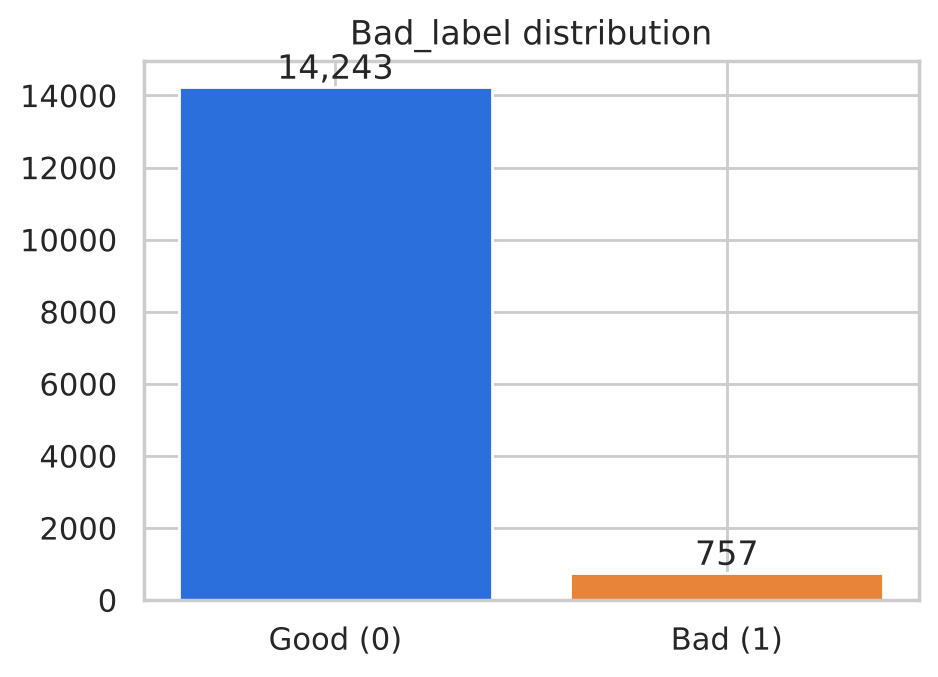

In [6]:
vc = demo['Bad_label'].value_counts()
print(vc, f"\nBad rate: {demo['Bad_label'].mean():.2%}")
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(['Good (0)', 'Bad (1)'], vc.values, color=['#2a6fdb', '#e8833a'])
for i, v in enumerate(vc.values): ax.text(i, v, f'{v:,}', ha='center', va='bottom')
ax.set_title('Bad_label distribution'); plt.show()

**Insight:** the target is heavily imbalanced (~5% bad).
**Decision:** use Gini / AUC instead of accuracy (a model saying "everyone is good" is 95% accurate and useless), stratify the train/test split, and use class weights in the models.

## 3. Account table

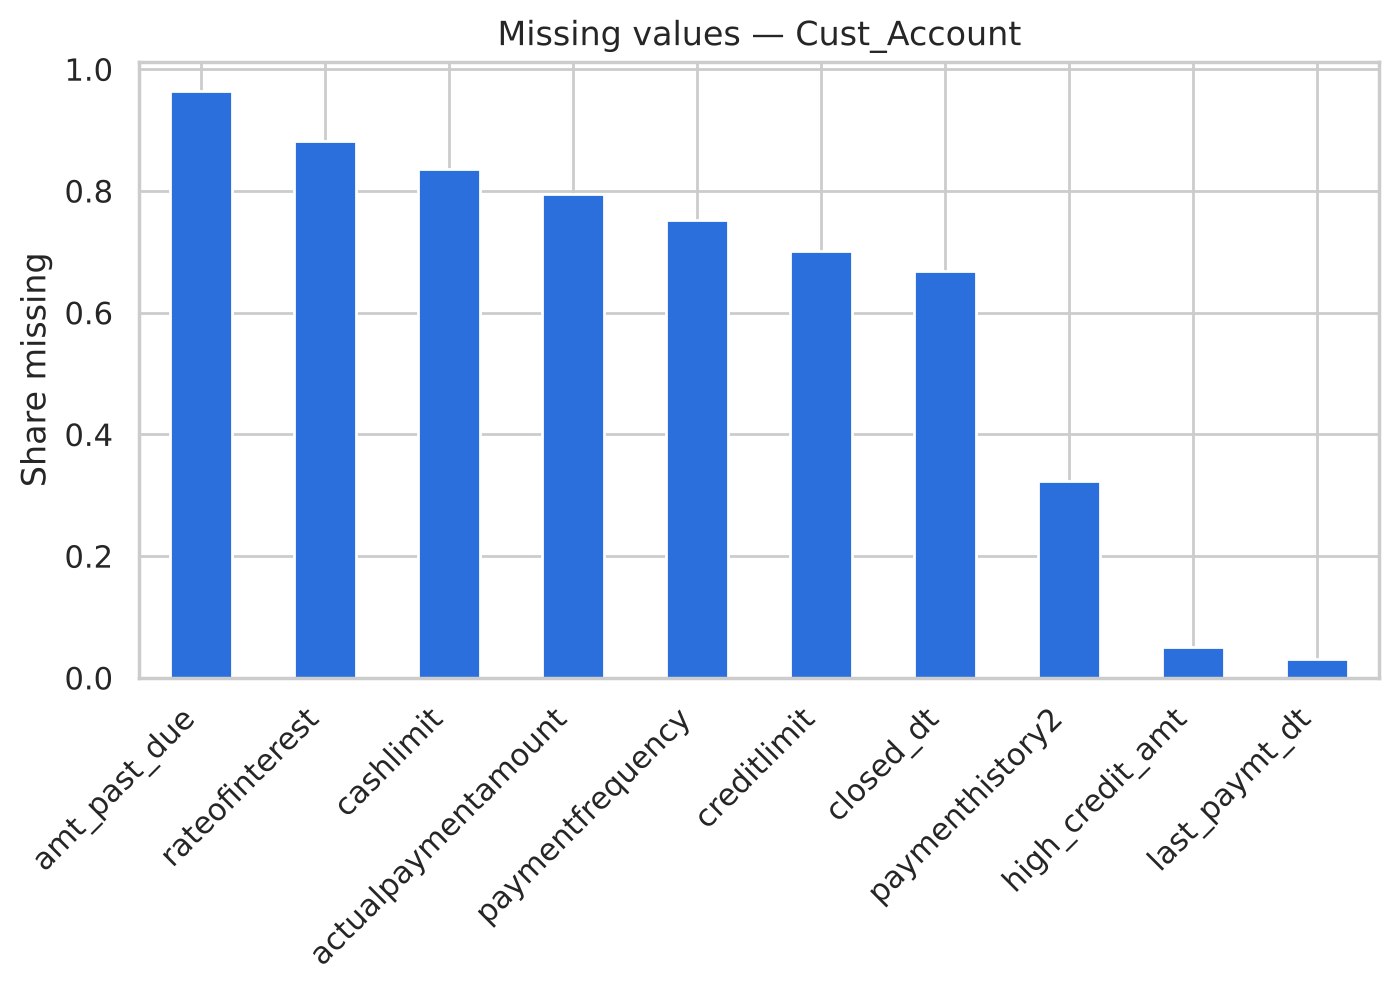

,amt_past_due,rateofinterest,cashlimit,actualpaymentamount,paymentfrequency,creditlimit,closed_dt,paymenthistory2,high_credit_amt,last_paymt_dt,dt_opened,upload_dt,customer_no,owner_indic,acct_type,opened_dt,reporting_dt,paymenthistory1,cur_balance_amt,paymt_end_dt,paymt_str_dt
missing_share,0.964,0.881,0.836,0.795,0.752,0.701,0.668,0.324,0.05,0.03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
miss = acc.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
miss[miss > 0].plot.bar(ax=ax, color='#2a6fdb'); ax.set_ylabel('Share missing'); ax.set_title('Missing values — Cust_Account')
plt.xticks(rotation=45, ha='right'); plt.show()
miss.round(3).to_frame('missing_share').T

count    15000.00
mean         6.42
std          2.67
min          1.00
25%          5.00
50%          6.00
75%          8.00
max         19.00
dtype: float64


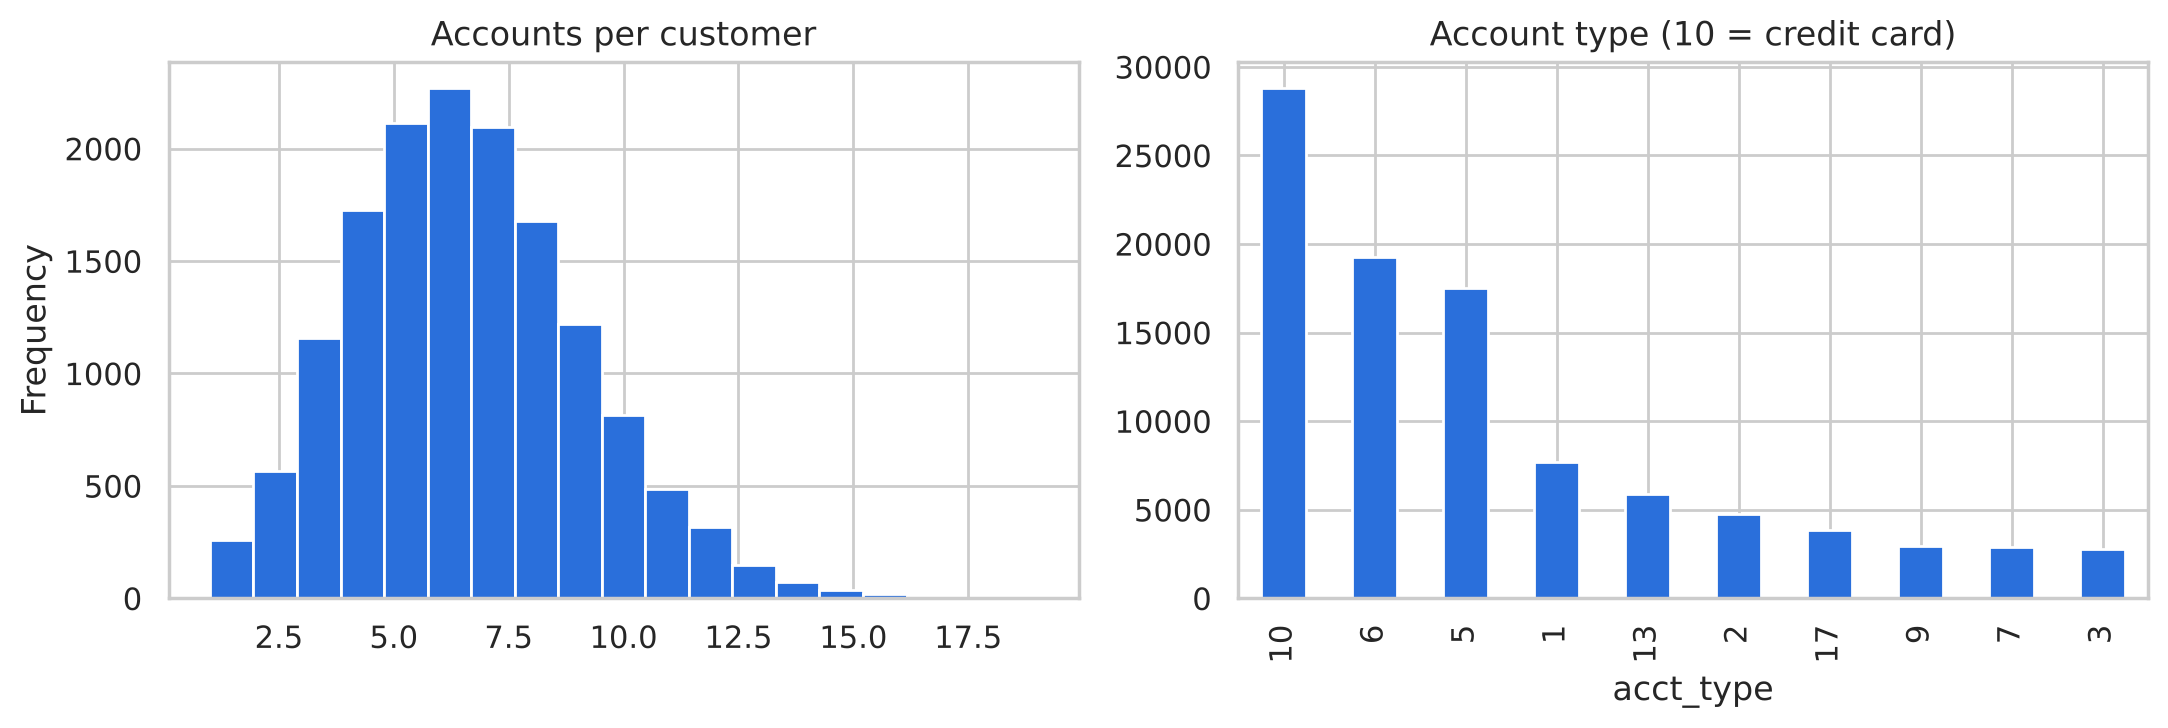

In [8]:
per_cust = acc.groupby('customer_no').size()
print(per_cust.describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
per_cust.plot.hist(bins=19, ax=axes[0], color='#2a6fdb'); axes[0].set_title('Accounts per customer')
acc['acct_type'].value_counts().head(10).plot.bar(ax=axes[1], color='#2a6fdb'); axes[1].set_title('Account type (10 = credit card)')
plt.tight_layout(); plt.show()

**Payment history strings.** `paymenthistory1` / `paymenthistory2` hold 3-character monthly codes, most recent month first: `000`/`STD` = paid on time, `005`–`999` = days past due, `XXX` = no information. Each string covers up to 18 months.

In [9]:
from feature_engineering import parse_history
ex = acc[['paymenthistory1', 'paymenthistory2']].iloc[3]
print('raw     :', ex['paymenthistory1'][:45], '...')
print('parsed  :', parse_history(ex['paymenthistory1'], ex['paymenthistory2'])[:15])

raw     : 000000000000000000000000STD000000STD000000STD ...
parsed  : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


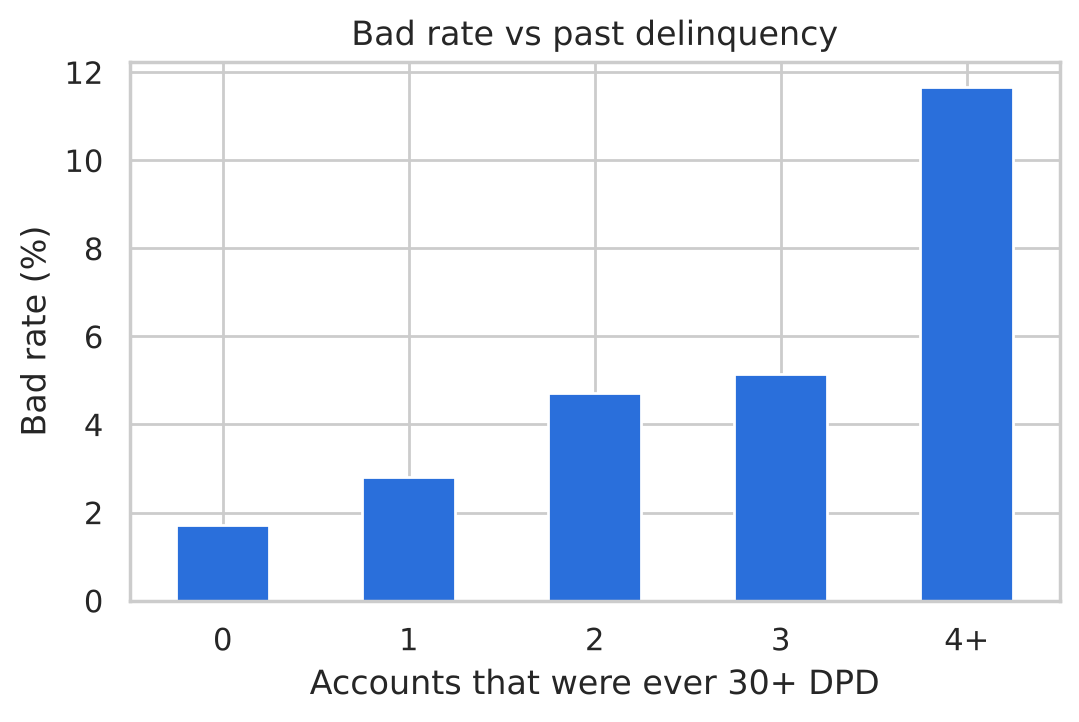

,mean,size
0,0.017146,3966
1,0.028051,3458
2,0.047210,2563
3,0.051576,1745
4+,0.116585,3268


In [10]:
acc['_hist'] = [parse_history(a, b) for a, b in zip(acc.paymenthistory1, acc.paymenthistory2)]
acc['_ever30'] = acc['_hist'].map(lambda h: int(np.nanmax(h) >= 30) if np.isfinite(np.nanmax(h)) else 0)
c = acc.groupby('customer_no')['_ever30'].sum().rename('accounts_ever_30p').to_frame().join(demo.set_index('customer_no')['Bad_label'])
t = c.groupby(c['accounts_ever_30p'].clip(upper=4))['Bad_label'].agg(['mean', 'size'])
t.index = ['0', '1', '2', '3', '4+']
ax = (t['mean'] * 100).plot.bar(color='#2a6fdb', figsize=(6, 3.5))
ax.set(xlabel='Accounts that were ever 30+ DPD', ylabel='Bad rate (%)', title='Bad rate vs past delinquency'); plt.xticks(rotation=0); plt.show()
t

**Insight:** past delinquency is the strongest signal. Customers with no account ever 30+ DPD have a bad rate of about 1.7%; it climbs steeply with each delinquent account.
**Decision:** parse the payment-history strings into monthly DPD and build count, max, mean and recency features from them.

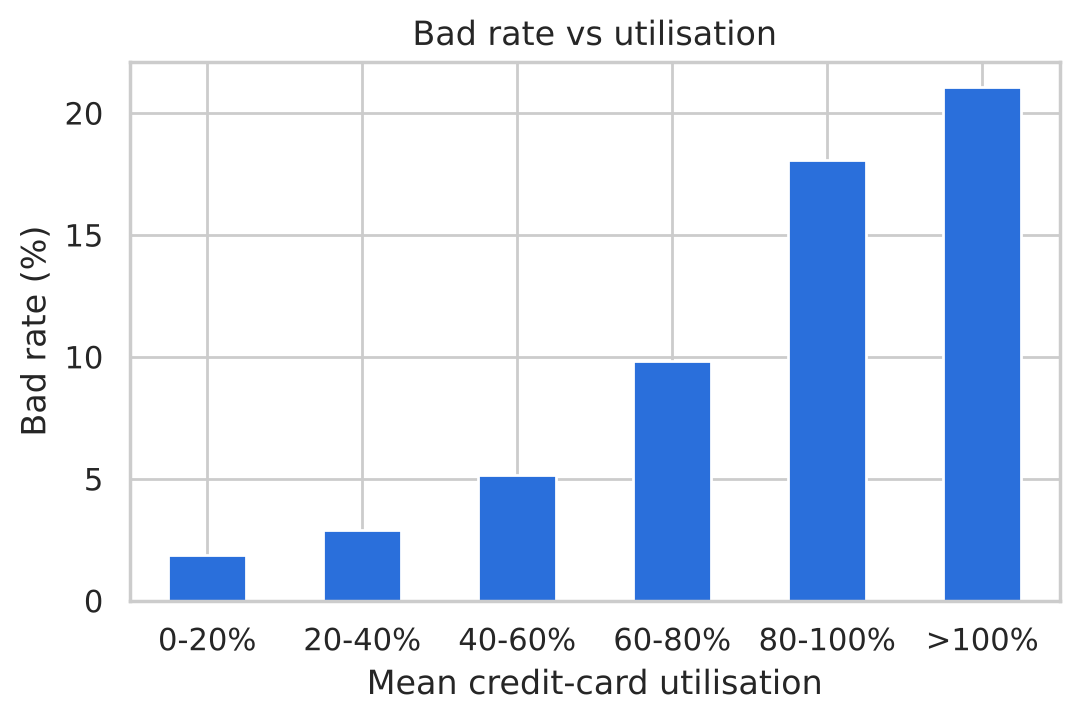

Customers without a credit card in history: 15.2%


In [11]:
card = acc[acc.acct_type == 10].copy()
card['util'] = card['cur_balance_amt'] / card['creditlimit']
cu = card.groupby('customer_no')['util'].mean().to_frame().join(demo.set_index('customer_no')['Bad_label'])
cu['band'] = pd.cut(cu['util'], [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0, 5], labels=['0-20%', '20-40%', '40-60%', '60-80%', '80-100%', '>100%'])
ax = (cu.groupby('band')['Bad_label'].mean() * 100).plot.bar(color='#2a6fdb', figsize=(6, 3.5))
ax.set(ylabel='Bad rate (%)', xlabel='Mean credit-card utilisation', title='Bad rate vs utilisation'); plt.xticks(rotation=0); plt.show()
print(f"Customers without a credit card in history: {1 - card.customer_no.nunique() / demo.customer_no.nunique():.1%}")

**Insight:** bad rate rises with card utilisation; customers above 80% utilisation are clearly riskier.
**Decision:** build `Ratio_currbalance_creditlimit` and `utilisation_trend`. About 15% of customers have no credit-card account, so these ratios are left missing for them (tree models handle it; the linear model imputes the median).

## 4. Enquiry table

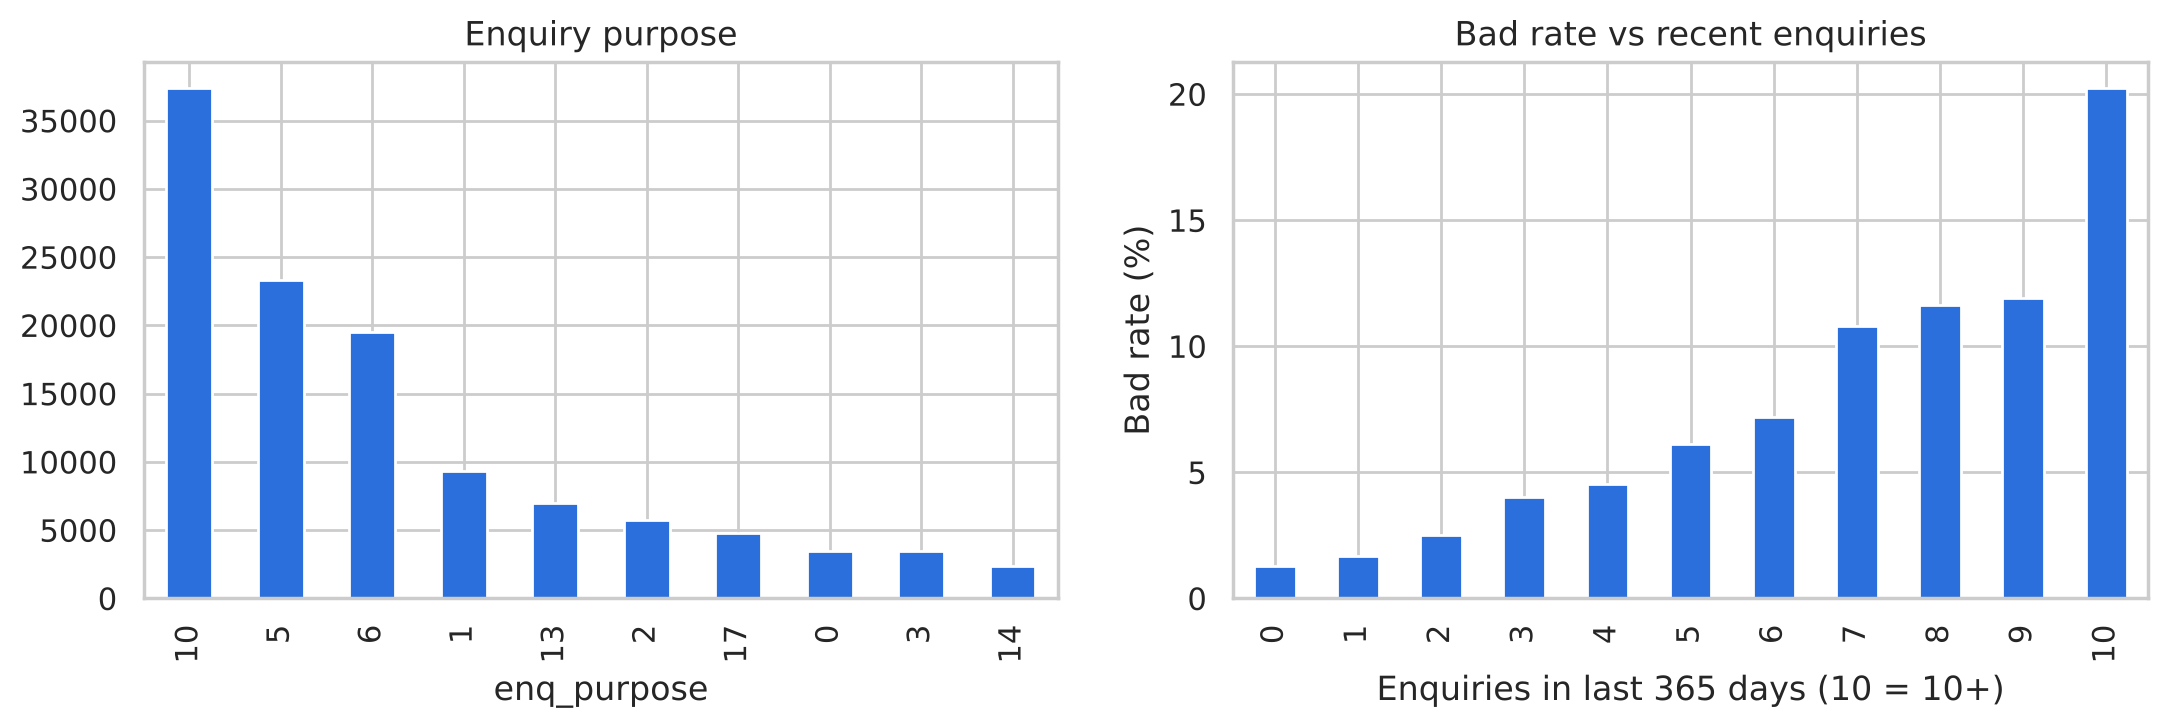

Customers with no enquiry record: 42


In [12]:
enq['enquiry_dt_p'] = pd.to_datetime(enq['enquiry_dt'], format='%d-%b-%y')
enq['days_ago'] = (pd.to_datetime(enq['dt_opened'], format='%d-%b-%y') - enq['enquiry_dt_p']).dt.days
e365 = enq[enq.days_ago <= 365].groupby('customer_no').size().reindex(demo.customer_no, fill_value=0)
d = pd.DataFrame({'enq365': e365.values, 'bad': demo['Bad_label'].values})
t = d.groupby(d['enq365'].clip(upper=10))['bad'].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
enq['enq_purpose'].value_counts().plot.bar(ax=axes[0], color='#2a6fdb'); axes[0].set_title('Enquiry purpose')
t.plot.bar(ax=axes[1], color='#2a6fdb'); axes[1].set(xlabel='Enquiries in last 365 days (10 = 10+)', ylabel='Bad rate (%)', title='Bad rate vs recent enquiries')
plt.tight_layout(); plt.show()
print(f'Customers with no enquiry record: {demo.customer_no.nunique() - enq.customer_no.nunique()}')

**Insight:** customers who shop for credit often in the last year are riskier — a classic "credit hungry" signal. Older enquiries matter less.
**Decision:** build enquiry counts for 30/90/180/365-day windows plus amount and purpose features; customers with no enquiries get counts of 0.

## 5. Demographics table

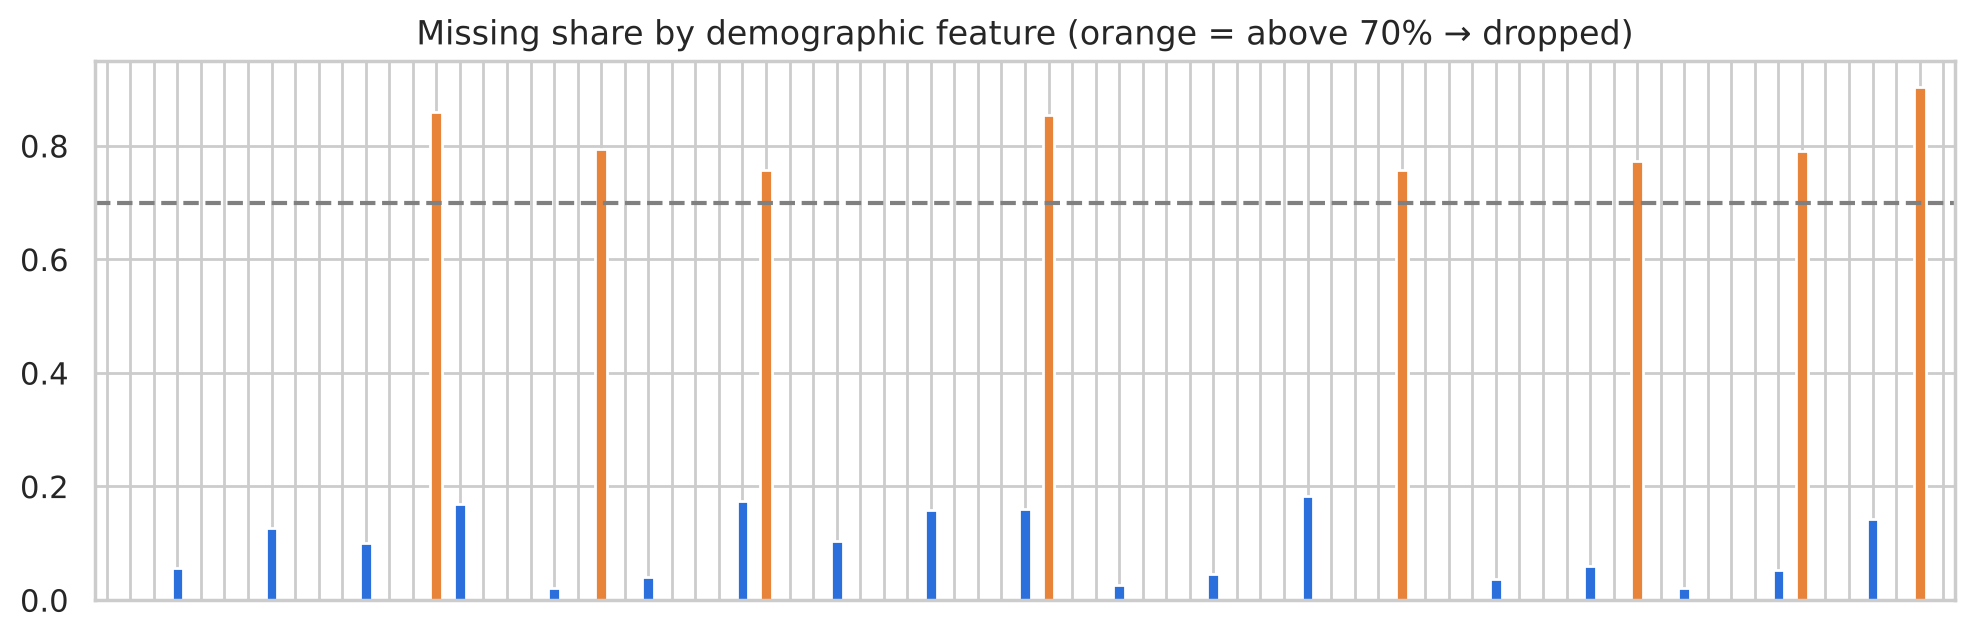

Above 70% missing : ['feature_15', 'feature_22', 'feature_29', 'feature_41', 'feature_56', 'feature_66', 'feature_73', 'feature_78']
Constant columns  : ['feature_5', 'feature_47']
Text columns      : ['feature_2', 'feature_12', 'feature_19', 'feature_21', 'feature_30', 'feature_38', 'feature_39', 'feature_44', 'feature_48', 'feature_57', 'feature_66', 'feature_75']


In [13]:
feats = [c for c in demo.columns if c.startswith('feature_')]
miss = demo[feats].isna().mean()
nun = demo[feats].nunique()
fig, ax = plt.subplots(figsize=(12, 3.5))
miss.plot.bar(ax=ax, color=np.where(miss > 0.7, '#e8833a', '#2a6fdb')); ax.axhline(0.7, ls='--', c='grey')
ax.set_title('Missing share by demographic feature (orange = above 70% → dropped)'); ax.set_xticklabels([]); plt.show()
print('Above 70% missing :', miss[miss > 0.7].index.tolist())
print('Constant columns  :', nun[nun <= 1].index.tolist())
print('Text columns      :', [c for c in feats if not pd.api.types.is_numeric_dtype(demo[c])])

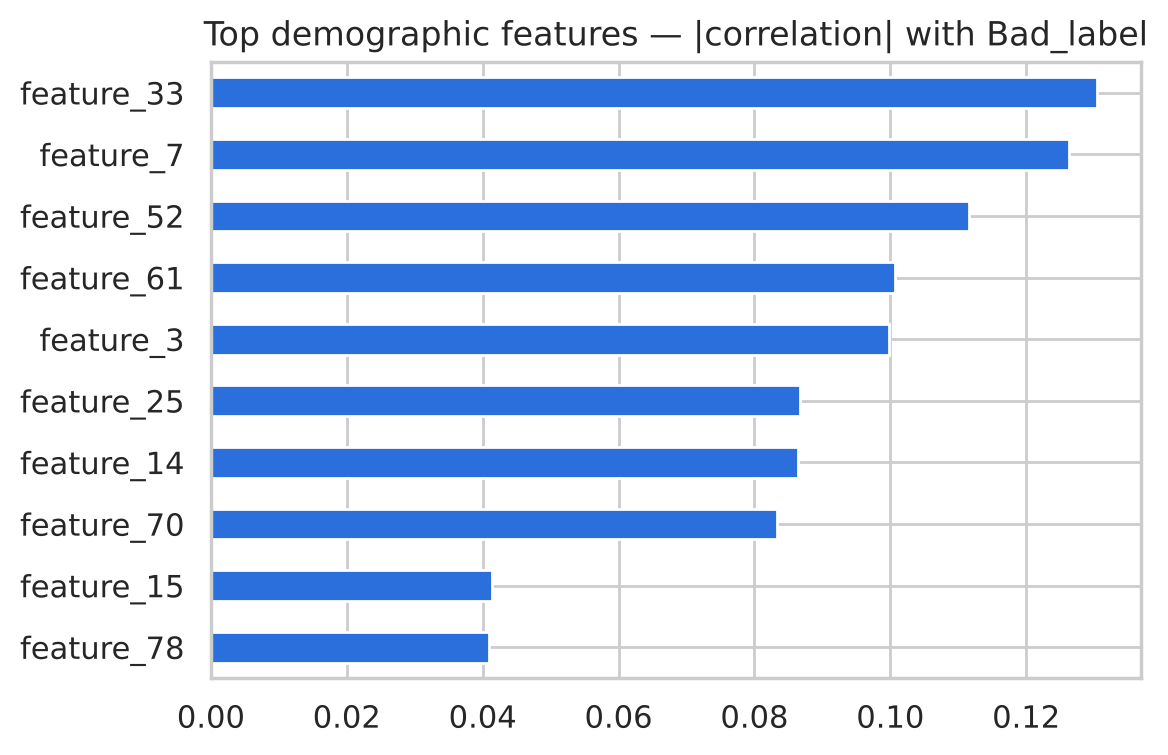

In [14]:
num = [c for c in feats if pd.api.types.is_numeric_dtype(demo[c]) and nun[c] > 1]
corr = demo[num + ['Bad_label']].corr()['Bad_label'].drop('Bad_label').abs().sort_values(ascending=False)
corr.head(10).plot.barh(color='#2a6fdb', figsize=(6, 4)).invert_yaxis(); plt.title('Top demographic features — |correlation| with Bad_label'); plt.show()

## 6. Summary — what we found and what we decided

| # | Finding | Decision |
|---|---|---|
| 1 | Target is imbalanced (~5% bad) | Gini/AUC metric, stratified split, class weights |
| 2 | Account table has many rows per customer | Aggregate everything to one row per customer |
| 3 | Payment history is coded as 3-char monthly DPD strings | Parse into monthly DPD → counts of 0-29 / 30+ / 60+ / 90+, max, mean, months since last 30+ |
| 4 | Past delinquency is the strongest risk signal | Prioritise DPD features (they top the gain table) |
| 5 | High card utilisation raises risk | Utilisation ratio and utilisation trend features |
| 6 | Recent credit enquiries raise risk | Enquiry counts by recency window |
| 7 | `amt_past_due`, `rateofinterest`, `cashlimit`, `paymentfrequency` are mostly empty | Don't use raw; use flags/aggregates only where meaningful |
| 8 | 8 demographic columns > 70% missing, 2 constant, 1 ID-like | Drop them |
| 9 | Several demographic columns are text categories | Frequency-encode (no target leakage); Y/N → 1/0 |
| 10 | Dates come as `DD-Mon-YY` text | Parse to dates and build durations (account age, last-payment gap, enquiry recency) |

→ Next: **Notebook 2 — Feature Engineering**